In [14]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt


from pathlib import Path
from tensorflow.keras import layers, models

PROJECT_DIR = Path.cwd().parent
DATASET_DIR = PROJECT_DIR / "dataset"
IMAGE_DIR = DATASET_DIR / "train_images"

train_df = pd.read_csv(DATASET_DIR / "train_split.csv")
val_df = pd.read_csv(DATASET_DIR / "val_split.csv")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Training images: 2929
Validation images: 733


Implementing a simple Artificial Neuron


In [6]:
#defining inputs
x1=0.8
x2=0.4
#defining weights
w1=0.5
w2=-0.2
#defining bias
bias = 0.1
#calculate weighted sum
z = (x1*w1) + (x2*w2) + bias
#applying ReLU activation
output = max(0,z)
print("weighted sum : ",z)
print("Neuron output : ",output)

weighted sum :  0.42000000000000004
Neuron output :  0.42000000000000004


In [ ]:
#Rectified Linear Unit Activation function
def relu(x):
    return max(0,x)
print(relu(-5))
print(relu(0))
print(relu(5))

0
0
5


In [ ]:
#Sigmoid Activation function
def sigmoid(x):
    return 1/(1+np.exp(-x))
print("Sigmoid(-5):", sigmoid(-5))
print("Sigmoid(0):", sigmoid(0))
print("Sigmoid(5):", sigmoid(5))

Sigmoid(-5): 0.0066928509242848554
Sigmoid(0): 0.5
Sigmoid(5): 0.9933071490757153


In [9]:
#Softmax activation function
#five output scores 
scores = np.array([2.0,1.0,3.0,0.5,0.2])
#Applying softmax
exp_scores = np.exp(scores-np.max(scores))
probabilities = exp_scores / np.sum(exp_scores)
classes = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Profilerative"
]
for category, probability in zip(classes, probabilities):
    print(f"{category}: {probability:.4f}")

print("\nProbability sum:", np.sum(probabilities))

No DR: 0.2235
Mild: 0.0822
Moderate: 0.6075
Severe: 0.0499
Profilerative: 0.0369

Probability sum: 1.0


Forward propogation

In [10]:
# Step 1: Define inputs
x1 = 2
x2 = 3


# Step 2: Calculate Hidden Neuron H1
z1 = (x1 * 0.5) + (x2 * -0.1) + 0.1

h1 = max(0, z1)  # ReLU


# Step 3: Calculate Hidden Neuron H2
z2 = (x1 * -0.3) + (x2 * 0.8) - 0.2

h2 = max(0, z2)  # ReLU


# Step 4: Calculate Output Neuron
z3 = (h1 * 0.4) + (h2 * 0.7) - 0.3


# Step 5: Apply Sigmoid
output = 1 / (1 + np.exp(-z3))


# Display results
print("Hidden Neuron H1:", h1)
print("Hidden Neuron H2:", h2)

print("Output before Sigmoid:", z3)
print("Final Prediction:", output)

Hidden Neuron H1: 0.7999999999999999
Hidden Neuron H2: 1.6000000000000003
Output before Sigmoid: 1.1400000000000001
Final Prediction: 0.7576796390037049


In [1]:
# Initial weight
weight = 4.0

# Learning rate
learning_rate = 0.1

# Perform gradient descent for 5 iterations

for step in range(5):

    # Calculate loss
    loss = weight ** 2

    # Calculate gradient
    gradient = 2 * weight

    # Update weight
    weight = weight - learning_rate * gradient

    print(
        f"Step {step + 1}: "
        f"Weight = {weight:.4f}, "
        f"Loss before update = {loss:.4f}"
    )

Step 1: Weight = 3.2000, Loss before update = 16.0000
Step 2: Weight = 2.5600, Loss before update = 10.2400
Step 3: Weight = 2.0480, Loss before update = 6.5536
Step 4: Weight = 1.6384, Loss before update = 4.1943
Step 5: Weight = 1.3107, Loss before update = 2.6844


In [2]:
import os
print(os.getpid())

22348


In [4]:
IMG_SIZE = 224
BATCH_SIZE = 8


def load_baseline_image(image_path, label):

    # Read image file
    image = tf.io.read_file(image_path)

    # Decode PNG image
    image = tf.image.decode_png(image, channels=3)

    # Resize while maintaining aspect ratio
    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE,
        antialias=True
    )

    # Normalize pixel values between 0 and 1
    image = tf.cast(image, tf.float32) / 255.0

    label = tf.cast(label, tf.int32)

    return image, label

In [5]:
def create_dataset(dataframe, training=False):

    image_paths = [
        str(IMAGE_DIR / f"{image_id}.png")
        for image_id in dataframe["id_code"]
    ]

    labels = dataframe["diagnosis"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            seed=42
        )

    dataset = dataset.map(
        load_baseline_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df, training=False)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [6]:
for images, labels in train_ds.take(1):

    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

    print("Data type:", images.dtype)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

    print("Labels:", labels.numpy())

Image shape: (8, 224, 224, 3)
Label shape: (8,)
Data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0000004
Labels: [0 2 0 0 3 0 4 3]


In [7]:
model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 4
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification section
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.4),

    # Five DR classes
    layers.Dense(5, activation="softmax")
])

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257,989 (1007.77 KB)

 Trainable params: 257,989 (1007.77 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_df["diagnosis"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["diagnosis"]
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:")
print(class_weights)

Class weights:
{0: 0.4056786703601108, 1: 1.979054054054054, 2: 0.7331664580725907, 3: 3.803896103896104, 4: 2.4822033898305085}


In [11]:
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=0.000001
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "cnn_baseline_best.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/5


c:\Users\Ayush\OneDrive\Documents\Diabetic-Retinopathy-Detection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


367/367 ━━━━━━━━━━━━━━━━━━━━ 88s 233ms/step - accuracy: 0.4264 - loss: 1.4743 - val_accuracy: 0.5907 - val_loss: 1.2149 - learning_rate: 0.0010
Epoch 2/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 83s 225ms/step - accuracy: 0.6132 - loss: 1.3134 - val_accuracy: 0.6630 - val_loss: 1.0510 - learning_rate: 0.0010
Epoch 3/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 82s 223ms/step - accuracy: 0.6337 - loss: 1.2606 - val_accuracy: 0.6603 - val_loss: 0.9588 - learning_rate: 0.0010
Epoch 4/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 83s 225ms/step - accuracy: 0.6391 - loss: 1.2321 - val_accuracy: 0.6235 - val_loss: 1.0063 - learning_rate: 0.0010
Epoch 5/5
367/367 ━━━━━━━━━━━━━━━━━━━━ 83s 226ms/step - accuracy: 0.6432 - loss: 1.2039 - val_accuracy: 0.6685 - val_loss: 0.9600 - learning_rate: 5.0000e-04


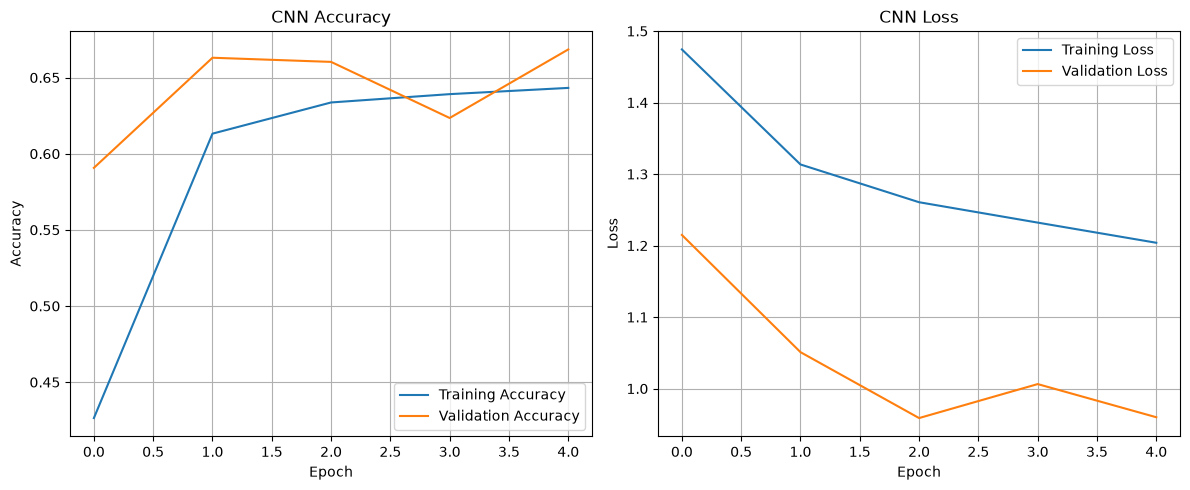

In [15]:
# Plot training and validation accuracy/loss

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)


# Loss graph
plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [17]:
best_model = tf.keras.models.load_model(
    MODEL_DIR / "cnn_baseline_best.keras"
)

print("Best CNN model loaded successfully!")

Best CNN model loaded successfully!


In [18]:
# Get actual labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in val_ds
])

# Generate prediction probabilities
y_prob = best_model.predict(val_ds)

# Convert probabilities into predicted classes
y_pred = np.argmax(y_prob, axis=1)

print("Actual labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)

print("Predictions generated successfully!")

92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 89ms/step
Actual labels: (733,)
Predicted labels: (733,)
Predictions generated successfully!


In [19]:
from sklearn.metrics import classification_report

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        zero_division=0
    )
)

                  precision    recall  f1-score   support

           No DR       0.93      0.89      0.91       361
            Mild       0.31      0.53      0.39        74
        Moderate       0.67      0.56      0.61       200
          Severe       0.14      0.03      0.04        39
Proliferative DR       0.12      0.19      0.15        59

        accuracy                           0.66       733
       macro avg       0.44      0.44      0.42       733
    weighted avg       0.69      0.66      0.67       733



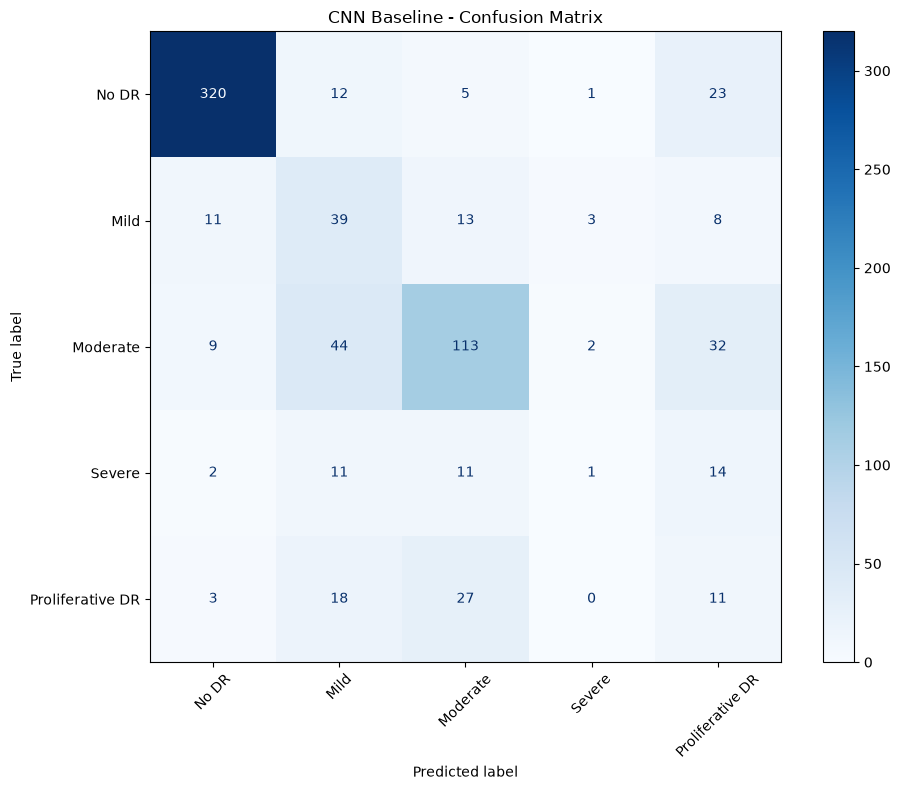

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("CNN Baseline - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()